# RQ4 pipeline, step 1: k-means versus Louvain

## Question
RQ4 asks whether the pseudo-genres are **real structure in the music or an artefact of k-means**. If two methods that work on different principles find similar groups in the same audio embeddings, the groups are more likely to be a property of the music than of one algorithm:
- **Method A, spherical k-means** (k = 32): every track goes to the nearest of k centres; it looks for compact, roughly equal "balls" in sound space and needs k in advance.
- **Method B, Louvain** (Peter, `notebooks/04`): tracks are linked to their 20 most similar tracks and the graph is cut where few links cross; it looks for densely connected regions and chooses the number of groups itself (26 to 28 here).

Peter's notebook ends with one hand-off number (ARI 0.43 between the two). A single number cannot say whether that is "similar" or "different", so this notebook asks:
1. **How similar are the partitions**, measured against how similar each method is *to itself* across random starts (the ceiling), at several k, and with k-means given the *same input* as Louvain?
2. **Where do they differ?** Which groups match one to one, which are split or merged?
3. **Is one of them better?** Each partition is judged by its own criterion and by the other method's criterion, and by an outside criterion (artists).
4. **Who disagrees?** Are disagreements spread evenly, or concentrated on tracks at the border between groups?

| § | Content |
|---|---|
| 1 | The partitions compared |
| 2 | Agreement, with ceilings |
| 3 | Where they differ: matches, splits and merges |
| 4 | Each partition judged by both objectives and by artists |
| 5 | Disagreement at the borders |
| 6 | All 848k tracks |
| 7 | Summary |

*Prerequisites:* `RQ4_pipeline/louvain_groups.csv.gz` (notebook 00), `RQ4_kmeans/kmeans_pseudogenres_k32.csv.gz`, `data/processed/emb50m_*.npy`, the artist mapping. Run time: about 3 minutes. Memory: about 2 GB.

## 0. Setup and parameters

In [1]:
import sys
import time
from itertools import combinations
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse

# ---------------- parameters (change here, then Run All) ----------------
K_GRID = [8, 16, 32, 64]  # k-means sizes for the agreement curve
N_SEEDS = 3               # k-means starts per k (as in RQ4_extension)
N_FIT = 150_000           # tracks used to fit k-means (as in RQ4_extension)
D, K_NN = 30, 20          # Louvain's PCA dimension and neighbours (Peter's final setting)
N_SHUFFLE = 5
SEED = 42

rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
REAL, NULL, ACC, KM = "#264653", "#9aa0a6", "#e76f51", "#e9c46a"

ROOT = Path.cwd()
while not (ROOT / "data" / "raw" / "yambda").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts"))
import louvain as LV
from rq4_tools import spherical_kmeans, kmeans_grid, nmi, contingency, pair_overlap, effective_number, item_map, modularity_sparse
DATA, PROC, OUT = ROOT / "data" / "raw" / "yambda", ROOT / "data" / "processed", ROOT / "RQ4_pipeline"
ari = LV.adjusted_rand_index
print("project root:", ROOT)

project root: C:\MSc DTU\Semester 3\01. CTDS\Music


## 1. The partitions compared

| Name | What | Tracks |
|---|---|---|
| **Louvain** (seeds 0-4) | Peter's final setting: top 50,000 tracks, PCA 30, 20 neighbours, γ = 1; other tracks assigned by neighbour vote (notebook 00) | 50k graph tracks, extended to all |
| **k-means, project file** | the saved k = 32 pseudo-genres of `RQ4_kmeans` (the ones the project reports) | all 848k |
| **k-means, k grid** | the RQ4_extension procedure (fit on 150,000 random tracks, assign all) for k = 8, 16, 32, 64 and for **k = the number of Louvain groups**, three starts each | all 848k |
| **k-means, same input** | spherical k-means on exactly Louvain's input (the 50,000 graph tracks in the 30-d PCA space), k = number of Louvain groups, three starts | 50k |

The last one separates two reasons the methods could disagree: the *algorithm* (balls versus dense regions) and the *input* (128-d embeddings of a random sample versus 30 PCA dimensions of the most played tracks).

In [2]:
t0 = time.time()
grp = pd.read_csv(OUT / "louvain_groups.csv.gz")
emb_ids = np.load(PROC / "emb50m_item_ids.npy"); assert np.array_equal(grp["item_id"].to_numpy(), emb_ids)
EN = np.load(PROC / "emb50m_norm.npy")
LSEEDS = [int(c.split("_s")[1]) for c in grp.columns if c.startswith("louvain_s")]
L_all = {s: grp[f"louvain_s{s}"].to_numpy() for s in LSEEDS}
g_rows = np.flatnonzero(grp["in_graph"].to_numpy())
K_MATCH = int(L_all[0][g_rows].max()) + 1
km_file = pd.read_csv(ROOT / "RQ4_kmeans/kmeans_pseudogenres_k32.csv.gz").set_index("item_id")["kmeans_cluster"].reindex(emb_ids).to_numpy()
km = kmeans_grid(EN, sorted(set(K_GRID + [K_MATCH])), N_SEEDS, N_FIT, SEED)          # {(k, s): labels of all tracks}
print(f"{len(g_rows):,} graph tracks; Louvain seed 0 has {K_MATCH} groups; k-means grid fitted ({time.time() - t0:.0f} s)")

# Louvain's own input, rebuilt exactly as in notebook 00 / Peter's notebook: graph tracks, most played first
order = g_rows[np.argsort(-grp["listens"].to_numpy()[g_rows], kind="stable")]
raw = np.load(PROC / "emb50m_embed.npy", mmap_mode="r")
Xg, _ = LV.preprocess(np.asarray(raw[order]), l2=True)
Zg = LV.l2_normalize(LV.fit_pca(Xg, D).scores).astype(np.float32)
idx_g, sims_g = LV.knn_cosine(Zg, K_NN)
km_same = {s: spherical_kmeans(Zg, K_MATCH, SEED + 100 * s)[1] for s in range(N_SEEDS)}                      # labels in `order`
# everything below on the graph tracks uses the row order `order`
Lg = {s: L_all[s][order] for s in LSEEDS}
KMg = {key: v[order] for key, v in km.items()}
KFg = km_file[order]
print(f"same-input k-means fitted ({time.time() - t0:.0f} s)")

50,000 graph tracks; Louvain seed 0 has 28 groups; k-means grid fitted (51 s)


same-input k-means fitted (74 s)


## 2. How similar are the two partitions?

**Measures.** *ARI* (adjusted Rand index) counts pairs of tracks that both partitions put together or both keep apart, corrected for chance (0 = chance, 1 = identical). It is strict when the numbers or sizes of groups differ.
*NMI* (normalised mutual information) asks how much knowing one partition tells about the other (0 = nothing, 1 = everything) and is less sensitive to different group sizes. We report both.

**Ceilings.** A method run twice with different random starts does not agree perfectly with itself. Agreement between methods can only be read against that: if k-means agrees with k-means at 0.6, an agreement of 0.4 with Louvain is two thirds of the way to "as similar as two runs of the same method".

**Chance.** The same comparison with one partition's labels shuffled.

50,000 graph tracks:
                                                              ARI   NMI
comparison                                                             
Louvain vs Louvain (5 seeds): ceiling for Louvain           0.799 0.857
k-means vs k-means, k = 28 (3 starts): ceiling for k-means  0.617 0.753
k-means vs k-means, k = 32 (3 starts)                       0.685 0.790
same-input k-means vs itself, k = 28                        0.640 0.775
Louvain vs k-means project file (k = 32)                    0.396 0.612
Louvain vs k-means, k = 32 (3 starts)                       0.446 0.628
Louvain vs k-means, k = 28 (3 starts)                       0.422 0.614
Louvain vs same-input k-means, k = 28                       0.467 0.655
same-input k-means vs k-means, k = 28                       0.457 0.665
chance: Louvain vs shuffled k-means (k = 32)               -0.000 0.003



by number of k-means groups:
    ARI_L_vs_K  NMI_L_vs_K  ARI_K_vs_K  NMI_K_vs_K
k                                                 
8        0.270       0.504       0.632       0.676
16       0.370       0.580       0.837       0.810
28       0.422       0.614       0.617       0.753
32       0.446       0.628       0.685       0.790
64       0.407       0.641       0.689       0.797


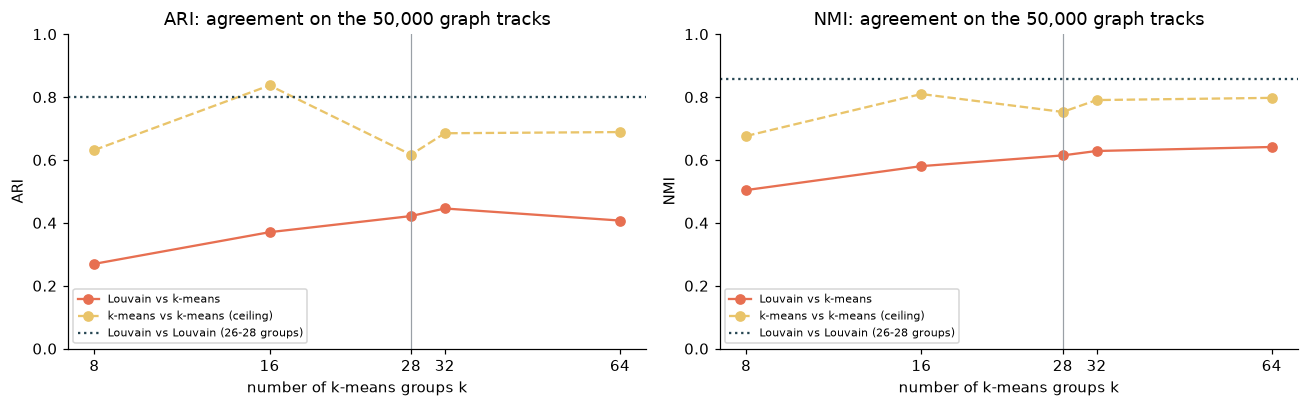

In [3]:
def pairs_mean(f, A, B=None):
    if B is None: return np.mean([f(A[a], A[b]) for a, b in combinations(list(A), 2)])
    return np.mean([f(a, b) for a in A for b in B])

Lv = [Lg[s] for s in LSEEDS]
rows = []
def add(name, A, B=None):
    rows.append(dict(comparison=name, ARI=pairs_mean(ari, A, B), NMI=pairs_mean(nmi, A, B)))
add("Louvain vs Louvain (5 seeds): ceiling for Louvain", {s: Lg[s] for s in LSEEDS})
add(f"k-means vs k-means, k = {K_MATCH} (3 starts): ceiling for k-means", {s: KMg[(K_MATCH, s)] for s in range(N_SEEDS)})
add("k-means vs k-means, k = 32 (3 starts)", {s: KMg[(32, s)] for s in range(N_SEEDS)})
add(f"same-input k-means vs itself, k = {K_MATCH}", km_same)
add("Louvain vs k-means project file (k = 32)", Lv, [KFg])
add("Louvain vs k-means, k = 32 (3 starts)", Lv, [KMg[(32, s)] for s in range(N_SEEDS)])
add(f"Louvain vs k-means, k = {K_MATCH} (3 starts)", Lv, [KMg[(K_MATCH, s)] for s in range(N_SEEDS)])
add(f"Louvain vs same-input k-means, k = {K_MATCH}", Lv, list(km_same.values()))
add(f"same-input k-means vs k-means, k = {K_MATCH}", list(km_same.values()), [KMg[(K_MATCH, s)] for s in range(N_SEEDS)])
add("chance: Louvain vs shuffled k-means (k = 32)", [Lg[0]], [rng.permutation(KFg) for _ in range(N_SHUFFLE)])
agree = pd.DataFrame(rows).set_index("comparison"); print(f"{len(order):,} graph tracks:"); print(agree.to_string(float_format=lambda x: f"{x:.3f}"))

curve = pd.DataFrame([dict(k=k, ARI_L_vs_K=pairs_mean(ari, Lv, [KMg[(k, s)] for s in range(N_SEEDS)]), NMI_L_vs_K=pairs_mean(nmi, Lv, [KMg[(k, s)] for s in range(N_SEEDS)]),
                           ARI_K_vs_K=pairs_mean(ari, {s: KMg[(k, s)] for s in range(N_SEEDS)}), NMI_K_vs_K=pairs_mean(nmi, {s: KMg[(k, s)] for s in range(N_SEEDS)}))
                      for k in sorted(set(K_GRID + [K_MATCH]))]).set_index("k")
print("\nby number of k-means groups:"); print(curve.to_string(float_format=lambda x: f"{x:.3f}"))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for a_, m in zip(ax, ["ARI", "NMI"]):
    a_.plot(curve.index, curve[f"{m}_L_vs_K"], "o-", color=ACC, label="Louvain vs k-means")
    a_.plot(curve.index, curve[f"{m}_K_vs_K"], "o--", color=KM, label="k-means vs k-means (ceiling)")
    a_.axhline(agree.loc["Louvain vs Louvain (5 seeds): ceiling for Louvain", m], color=REAL, ls=":", label=f"Louvain vs Louvain ({K_MATCH - 2}-{K_MATCH} groups)")
    a_.axvline(K_MATCH, color=NULL, lw=0.8); a_.set_xscale("log"); a_.set_xticks(curve.index); a_.set_xticklabels(curve.index); a_.minorticks_off()
    a_.set(title=f"{m}: agreement on the 50,000 graph tracks", xlabel="number of k-means groups k", ylabel=m, ylim=(0, 1)); a_.legend(fontsize=7)
plt.tight_layout(); plt.show()

### 2.1 Reading the agreement

**The two methods agree well above chance, but clearly less than each agrees with itself.** On the 50,000 graph tracks:

| | ARI | NMI |
|---|---|---|
| Louvain vs Louvain (five seeds) | 0.80 | 0.86 |
| k-means vs k-means, k = 28 / 32 (three starts) | 0.62 / 0.69 | 0.75 / 0.79 |
| **Louvain vs k-means**, k = 28 / 32 / project file | **0.42 / 0.45 / 0.40** | **0.61 / 0.63 / 0.61** |
| chance (shuffled labels) | 0.00 | 0.00 |

Louvain is the more reproducible method (0.80 against 0.62 to 0.69). Against the k-means ceiling, the cross-method agreement reaches about **two thirds in ARI** (0.42 of 0.62 at k = 28) and **four fifths in NMI** (0.61 of 0.75). Peter's hand-off value (0.43) lies in this range; the project file gives 0.40, a refitted k = 32 gives 0.45.

**The agreement does not depend on a lucky k.** It is lowest when k-means has far fewer groups than Louvain (ARI 0.27 at k = 8), rises to 0.42 to 0.45 at k = 28 to 32 and stays there at k = 64 (0.41; NMI keeps rising slightly, to 0.64). k = 16 is the most reproducible k-means setting (0.84 between starts) but agrees less with Louvain (0.37), because Louvain's 28 groups have to be merged to match it.

**Algorithm and input matter about equally.** Given exactly Louvain's input (30 PCA dimensions of the 50,000 graph tracks), k-means agrees with Louvain at ARI 0.47, and with ordinary k-means on the full 128 dimensions at 0.46. Changing only the input moves k-means about as far as changing the algorithm does. Neither choice produces structure of its own; both cut the same sound space in somewhat different places.

## 3. Where do they differ?

**Contingency table.** Rows are Louvain groups (seed 0), columns the project's 32 k-means pseudo-genres; each cell counts the graph tracks in both.
For every group we ask how concentrated it is in the other partition:
- the share of a Louvain group that lies in its **largest** k-means genre (1 = the group is inside one pseudo-genre);
- the number of pseudo-genres needed to cover 80% of the group;
- and the same from the k-means side.

**Matches, splits and merges.** A Louvain group L and a pseudo-genre K are a **one-to-one match** if more than half of L lies in K *and* more than half of K lies in L. A pseudo-genre is **split** if no Louvain group holds more than half of it.
A Louvain group **merges** pseudo-genres if two or more pseudo-genres have more than half of their tracks in it.

**Pair view.** P(same Louvain | same k-means) is the share of track pairs in one pseudo-genre that are also in one Louvain group, and the reverse; the coarser partition has the higher value on the left.

Louvain groups: 28; k-means genres: 32
median share of a Louvain group in its top k-means genre 0.63; groups with > 50%: 18 of 28
median share of a k-means genre in its top Louvain group 0.68; genres with > 50%: 23 of 32
one-to-one matches: 9 (covering 30% of the tracks)
k-means genres split (no Louvain group holds > 50%): 9; Louvain groups that merge >= 2 genres: 5 {2: [9, 11], 7: [1, 17], 16: [24, 29], 18: [7, 18, 19], 24: [13, 23, 25, 27]}
pairs: P(same Louvain | same k-means) = 0.43, P(same k-means | same Louvain) = 0.45
effective number of groups (exp entropy of sizes): Louvain 22.4 of 28, k-means 24.1 of 32


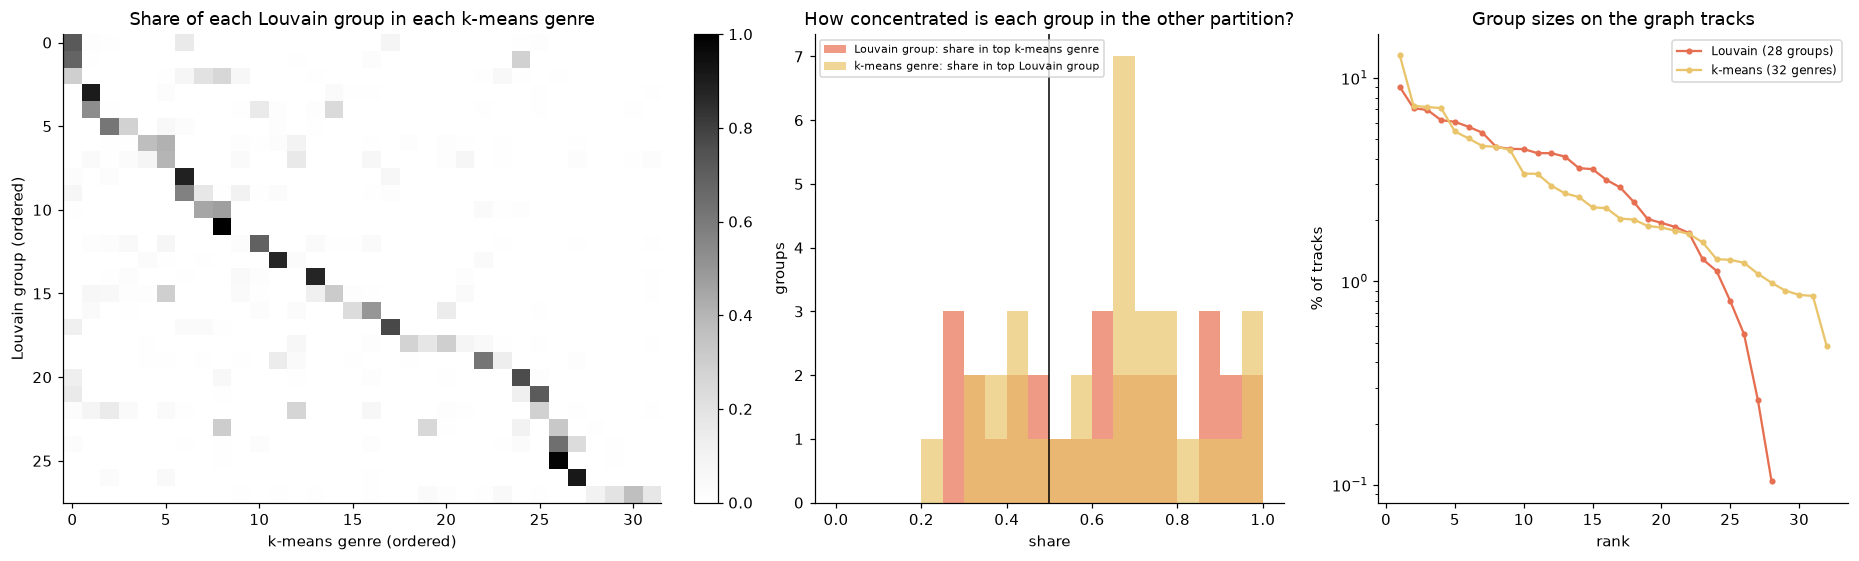

In [4]:
T = contingency(Lg[0], KFg)                       # rows: Louvain groups, columns: k-means genres
row_share = T / T.sum(1, keepdims=True); col_share = T / T.sum(0, keepdims=True)
def need80(shares):
    s = np.sort(shares)[::-1]; return int(np.searchsorted(np.cumsum(s), 0.8) + 1)
L_tab = pd.DataFrame({"tracks": T.sum(1).astype(int), "share_in_top_kmeans_genre": row_share.max(1), "kmeans_genres_for_80pct": [need80(r_) for r_ in row_share],
                      "top_kmeans_genre": T.argmax(1)})
K_tab = pd.DataFrame({"tracks": T.sum(0).astype(int), "share_in_top_louvain_group": col_share.max(0), "louvain_groups_for_80pct": [need80(c) for c in col_share.T],
                      "top_louvain_group": T.argmax(0)})
match = [(l, k) for l in range(T.shape[0]) for k in range(T.shape[1]) if row_share[l, k] > 0.5 and col_share[l, k] > 0.5]
split = [k for k in range(T.shape[1]) if col_share[:, k].max() <= 0.5]
merge = {l: np.flatnonzero(col_share[l] > 0.5).tolist() for l in range(T.shape[0]) if (col_share[l] > 0.5).sum() >= 2}
p_LK, p_KL = pair_overlap(KFg, Lg[0])
print(f"Louvain groups: {T.shape[0]}; k-means genres: {T.shape[1]}")
print(f"median share of a Louvain group in its top k-means genre {L_tab.share_in_top_kmeans_genre.median():.2f}; groups with > 50%: {(L_tab.share_in_top_kmeans_genre > 0.5).sum()} of {len(L_tab)}")
print(f"median share of a k-means genre in its top Louvain group {K_tab.share_in_top_louvain_group.median():.2f}; genres with > 50%: {(K_tab.share_in_top_louvain_group > 0.5).sum()} of {len(K_tab)}")
print(f"one-to-one matches: {len(match)} (covering {sum(T[l, k] for l, k in match) / T.sum():.0%} of the tracks)")
print(f"k-means genres split (no Louvain group holds > 50%): {len(split)}; Louvain groups that merge >= 2 genres: {len(merge)} {merge}")
print(f"pairs: P(same Louvain | same k-means) = {p_LK:.2f}, P(same k-means | same Louvain) = {p_KL:.2f}")
print(f"effective number of groups (exp entropy of sizes): Louvain {effective_number(Lg[0]):.1f} of {T.shape[0]}, k-means {effective_number(KFg):.1f} of {T.shape[1]}")

# order rows and columns so that matching groups lie on the diagonal
col_order = np.argsort(K_tab.top_louvain_group.to_numpy() * 1000 - K_tab.share_in_top_louvain_group.to_numpy(), kind="stable")
row_order = np.argsort([np.where(col_order == k)[0][0] for k in L_tab.top_kmeans_genre], kind="stable")
fig, ax = plt.subplots(1, 3, figsize=(17, 5.2), gridspec_kw=dict(width_ratios=[1.4, 1, 1]))
im = ax[0].imshow(row_share[row_order][:, col_order], cmap="Greys", vmin=0, vmax=1, aspect="auto")
ax[0].set(title="Share of each Louvain group in each k-means genre", xlabel="k-means genre (ordered)", ylabel="Louvain group (ordered)"); plt.colorbar(im, ax=ax[0], fraction=0.04)
ax[1].hist(L_tab.share_in_top_kmeans_genre, bins=np.linspace(0, 1, 21), color=ACC, alpha=.7, label="Louvain group: share in top k-means genre")
ax[1].hist(K_tab.share_in_top_louvain_group, bins=np.linspace(0, 1, 21), color=KM, alpha=.7, label="k-means genre: share in top Louvain group")
ax[1].axvline(0.5, color="k", lw=1); ax[1].set(title="How concentrated is each group in the other partition?", xlabel="share", ylabel="groups"); ax[1].legend(fontsize=7)
sz_L = np.sort(np.bincount(Lg[0]))[::-1] / len(order) * 100; sz_K = np.sort(np.bincount(KFg, minlength=32))[::-1] / len(order) * 100
ax[2].plot(np.arange(1, len(sz_L) + 1), sz_L, "o-", color=ACC, ms=3, label=f"Louvain ({len(sz_L)} groups)"); ax[2].plot(np.arange(1, len(sz_K) + 1), sz_K, "o-", color=KM, ms=3, label="k-means (32 genres)")
ax[2].set(title="Group sizes on the graph tracks", xlabel="rank", ylabel="% of tracks", yscale="log"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 3.1 Reading where they differ

**About a third of the tracks fall in regions both methods find almost identically; elsewhere groups are split or merged across borders.**
- **9 one-to-one matches** (a Louvain group and a pseudo-genre that each have more than half of their tracks in the other) cover **30% of the tracks** (the dark diagonal cells).
- 18 of 28 Louvain groups lie mostly (> 50%) inside one pseudo-genre (median share 0.63), and 23 of 32 pseudo-genres lie mostly inside one Louvain group (median 0.68).
- **5 Louvain groups merge** two to four pseudo-genres each (groups 2, 7, 16, 18 and 24 of seed 0); **9 pseudo-genres are split** without a majority Louvain group.
- The pair view is balanced: P(same Louvain | same k-means) = 0.43 and P(same k-means | same Louvain) = 0.45. Neither partition is simply a coarser version of the other; they differ *crosswise*, Louvain merging in some regions and splitting in others.

**Group sizes differ in shape.** Louvain has a few very small groups (the last three hold under 1% of the tracks each) and many medium ones, while k-means spreads tracks more evenly over its 32 genres. The effective numbers of groups are similar (22.4 of 28 against 24.1 of 32). Louvain follows the density of the data; k-means tends towards balls of similar size.

## 4. Is one partition better? Each judged by both objectives and by artists

Each method optimises its own criterion, so it is no surprise if it wins on it. The informative question is how well each partition does on the **other** method's criterion, and on a criterion neither optimises:
- **k-means criterion:** mean cosine similarity of a track to its group's centre (in the full 128-d embedding);
- **Louvain criterion:** modularity of the partition on Louvain's kNN graph (the share of link weight inside groups minus what random wiring would put there);
- **outside criterion:** artist purity, the share of an artist's tracks in their most common group (artists with at least 5 graph tracks), minus the same with shuffled labels. Neither method ever sees artist IDs.

Shuffled labels (sizes kept) give the floor for each criterion.

In [5]:
A_knn = sparse.coo_matrix((np.maximum(sims_g, 0).ravel(), (np.repeat(np.arange(len(order)), K_NN), idx_g.ravel())), shape=(len(order),) * 2).tocsr()
A_knn = A_knn.maximum(A_knn.T).tocsr()                     # the union kNN graph Louvain was run on
X128 = EN[order]
L_ = int(emb_ids.max()) + 1
artist = item_map(DATA / "artist_item_mapping.parquet", "artist_id", L_)[emb_ids[order]]
big = pd.Series(artist[artist >= 0]).value_counts(); big = big[big >= 5].index; amask = np.isin(artist, big)
def purity(lab):
    t = pd.DataFrame({"a": artist[amask], "g": lab[amask]})
    return (t.groupby(["a", "g"]).size().groupby("a").max() / t.groupby("a").size()).mean()
def centre_cos(lab):
    _, lab = np.unique(lab, return_inverse=True); C = np.zeros((lab.max() + 1, X128.shape[1])); np.add.at(C, lab, X128)
    C /= np.linalg.norm(C, axis=1, keepdims=True); return float((X128 * C[lab]).sum(1).mean())
cands = {f"Louvain ({K_MATCH} groups)": Lg[0], "k-means project file (32)": KFg, f"k-means, k = {K_MATCH}": KMg[(K_MATCH, 0)],
         f"same-input k-means, k = {K_MATCH}": km_same[0], "shuffled Louvain labels": rng.permutation(Lg[0])}
pur_floor = np.mean([purity(rng.permutation(Lg[0])) for _ in range(3)])
crit = pd.DataFrame([dict(partition=n, groups=len(np.unique(l)), effective_groups=effective_number(np.unique(l, return_inverse=True)[1]), mean_cos_to_centre=centre_cos(l),
                          modularity_on_knn_graph=modularity_sparse(A_knn, l), artist_purity=purity(l), artist_purity_lift=purity(l) - pur_floor) for n, l in cands.items()]).set_index("partition")
print(f"{len(order):,} graph tracks; {amask.sum():,} of them by {len(big):,} artists with >= 5 graph tracks")
print(crit.to_string(float_format=lambda x: f"{x:.3f}"))

50,000 graph tracks; 35,300 of them by 2,550 artists with >= 5 graph tracks
                            groups  effective_groups  mean_cos_to_centre  modularity_on_knn_graph  artist_purity  artist_purity_lift
partition                                                                                                                           
Louvain (28 groups)             28            22.439               0.681                    0.847          0.844               0.624
k-means project file (32)       32            24.144               0.701                    0.762          0.790               0.571
k-means, k = 28                 28            22.207               0.693                    0.760          0.786               0.567
same-input k-means, k = 28      28            26.988               0.710                    0.786          0.787               0.568
shuffled Louvain labels         28            22.439               0.386                    0.000          0.219              

### 4.1 Reading the criteria

| Criterion | Louvain | k-means (file, k = 32) | k-means, k = 28 | same-input k-means | shuffled |
|---|---|---|---|---|---|
| Mean cosine to group centre (k-means criterion) | 0.681 | 0.701 | 0.693 | **0.710** | 0.386 |
| Modularity on the kNN graph (Louvain criterion) | **0.847** | 0.762 | 0.760 | 0.786 | 0.000 |
| Artist purity (lift over shuffled) | **0.844 (0.62)** | 0.790 (0.57) | 0.786 (0.57) | 0.787 (0.57) | 0.219 (0) |

- **Each method wins its own criterion but does well on the other's.** Louvain reaches 97% of k-means' centre cosine (0.681 against 0.701), and k-means reaches 90% of Louvain's modularity (0.762 against 0.847). Both are far from the shuffled floor (0.386 and 0.000). Neither partition is a poor solution by the other method's standard: they are two good cuts of the same structure.
- **On the outside criterion Louvain is better.** Neither method sees artist IDs, yet an artist's tracks end up in one Louvain group more often than in one pseudo-genre (purity 0.84 against 0.79; lift 0.62 against 0.57). Following the neighbourhood graph keeps artists together better than cutting the space into balls. This holds at the same number of groups (k = 28: 0.79) and with the same input (0.79), so it is a property of the algorithm, not of k or of the input.

## 5. Do the methods disagree at the borders?

If the music forms a continuum with denser and thinner regions, any method has to draw borders somewhere, and two methods will draw them in slightly different places. Then disagreement should be concentrated on tracks **near a border** and rare in the **cores**.
If instead the methods found unrelated structure, disagreement would be spread evenly.

**Agreement of a track:** its k-means genre is the genre that most of its Louvain group falls into (the "matched genre" of its group).
**How central a track is**, measured separately for each method:
- k-means: the *margin*, cosine to its own centre minus cosine to the second-closest centre (small = between two genres);
- Louvain: the share of its graph neighbours' link weight that lies inside its own group (small = linked to other groups).

agreement overall: 58.5% of graph tracks
by k-means margin quintile: {'lowest 20%': 0.446, '2': 0.476, '3': 0.582, '4': 0.679, 'highest 20%': 0.74}
by Louvain inside-share quintile: {'lowest 20%': 0.379, '2': 0.545, '3': 0.69, '4': 0.66, 'highest 20%': 0.65}
core tracks (top half on both): 36% of tracks, agreement 74.4%; border tracks (lowest 20% margin and lower half inside share): 11%, agreement 38.1%


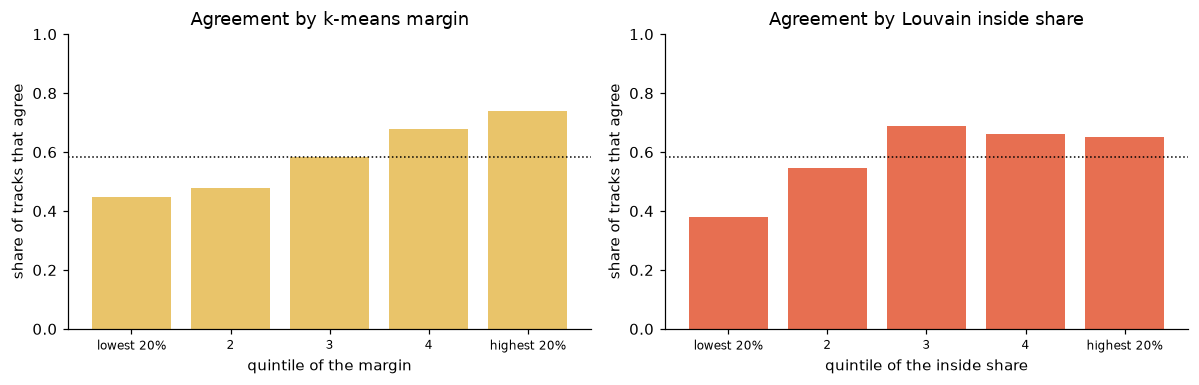

In [6]:
Ckf = np.zeros((32, X128.shape[1])); np.add.at(Ckf, KFg, X128); Ckf /= np.linalg.norm(Ckf, axis=1, keepdims=True)
cs = X128 @ Ckf.T; srt = np.sort(cs, axis=1); margin = srt[:, -1] - srt[:, -2]
same = Lg[0][idx_g] == Lg[0][:, None]; w = np.maximum(sims_g, 0); inside = (w * same).sum(1) / w.sum(1)
agree_t = KFg == L_tab.top_kmeans_genre.to_numpy()[Lg[0]]
Q5 = ["lowest 20%", "2", "3", "4", "highest 20%"]
quint = lambda x: pd.qcut(pd.Series(x).rank(method="first"), 5, labels=Q5)     # ranks: ties (many inside shares of 1.0) are split evenly
bins = pd.DataFrame({"agree": agree_t, "k-means margin": quint(margin), "Louvain inside share": quint(inside)})
t1 = bins.groupby("k-means margin", observed=True)["agree"].mean(); t2 = bins.groupby("Louvain inside share", observed=True)["agree"].mean()
core = (margin >= np.quantile(margin, 0.5)) & (inside >= np.quantile(inside, 0.5))
border = (margin < np.quantile(margin, 0.2)) & (inside < np.quantile(inside, 0.5))
print(f"agreement overall: {agree_t.mean():.1%} of graph tracks")
print("by k-means margin quintile:", {k_: round(v, 3) for k_, v in t1.items()})
print("by Louvain inside-share quintile:", {k_: round(v, 3) for k_, v in t2.items()})
print(f"core tracks (top half on both): {core.mean():.0%} of tracks, agreement {agree_t[core].mean():.1%}; border tracks (lowest 20% margin and lower half inside share): {border.mean():.0%}, agreement {agree_t[border].mean():.1%}")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].bar(range(len(t1)), t1.values, color=KM); ax[0].set_xticks(range(len(t1))); ax[0].set_xticklabels(t1.index, fontsize=8); ax[0].set(title="Agreement by k-means margin", xlabel="quintile of the margin", ylabel="share of tracks that agree", ylim=(0, 1))
ax[1].bar(range(len(t2)), t2.values, color=ACC); ax[1].set_xticks(range(len(t2))); ax[1].set_xticklabels(t2.index, fontsize=8); ax[1].set(title="Agreement by Louvain inside share", xlabel="quintile of the inside share", ylabel="share of tracks that agree", ylim=(0, 1))
for a_ in ax: a_.axhline(agree_t.mean(), color="k", lw=1, ls=":")
plt.tight_layout(); plt.show()

### 5.1 Reading the borders

**Disagreement sits at the borders.** Overall, 58.5% of the graph tracks are in the pseudo-genre that their Louvain group mostly maps to. Agreement rises steadily with the k-means margin, from **45%** for the 20% of tracks closest to a second centre to **74%** for the 20% most clearly inside their pseudo-genre.
It also rises with the Louvain inside share, from **38%** for the tracks most linked to other groups to 65-69% in the upper three quintiles (those three quintiles are almost all tracks whose links lie *entirely* inside their group, inside share 1.0, split by rank, so they do not differ from each other).
**Core tracks** (upper half on both measures, 36% of the tracks) agree **74%** of the time, **border tracks** (lowest 20% of margin and lower half of inside share, 11%) only **38%**.

**How to read it.** This is the pattern expected if the sound space is a **continuum with denser regions**, not a set of separate islands: both methods find the dense regions and disagree mainly about where to draw the lines between them. The k-means baseline already pointed this way (weak absolute silhouette of about 0.2, no elbow in k).

## 6. All 848k tracks
The following notebooks use the groups for all tracks (Louvain extended by neighbour vote, notebook 00). We repeat the headline agreement on all tracks and separately on the tracks outside the graph.

In [7]:
outside = ~grp["in_graph"].to_numpy()
rows = []
for name, msk in [("all tracks", np.ones(len(grp), bool)), ("graph tracks (50k)", ~outside), ("non-graph tracks (extended)", outside)]:
    rows.append(dict(tracks=name, n=int(msk.sum()), ARI_vs_kmeans_file=np.mean([ari(L_all[s][msk], km_file[msk]) for s in LSEEDS]),
                     NMI_vs_kmeans_file=np.mean([nmi(L_all[s][msk], km_file[msk]) for s in LSEEDS]),
                     ARI_Louvain_seeds=pairs_mean(ari, {s: L_all[s][msk] for s in LSEEDS}), ARI_kmeans_starts_k32=pairs_mean(ari, {s: km[(32, s)][msk] for s in range(N_SEEDS)})))
allt = pd.DataFrame(rows).set_index("tracks"); print(allt.to_string(float_format=lambda x: f"{x:.3f}"))
summary = pd.concat([agree.assign(level="graph tracks"), curve.reset_index().assign(comparison=lambda d: "k = " + d.k.astype(str)).set_index("comparison").assign(level="k curve")])
summary.to_csv(OUT / "compare_agreement.csv"); crit.to_csv(OUT / "compare_criteria.csv")
pd.DataFrame({"louvain_group": range(len(L_tab)), **L_tab}).to_csv(OUT / "compare_louvain_groups_vs_kmeans.csv", index=False)
print("wrote RQ4_pipeline/compare_agreement.csv, compare_criteria.csv, compare_louvain_groups_vs_kmeans.csv")

                                  n  ARI_vs_kmeans_file  NMI_vs_kmeans_file  ARI_Louvain_seeds  ARI_kmeans_starts_k32
tracks                                                                                                               
all tracks                   847921               0.327               0.590              0.802                  0.643
graph tracks (50k)            50000               0.396               0.612              0.799                  0.685
non-graph tracks (extended)  797921               0.324               0.588              0.804                  0.643
wrote RQ4_pipeline/compare_agreement.csv, compare_criteria.csv, compare_louvain_groups_vs_kmeans.csv


## 7. Summary and limitations

**Answer to the comparison part of RQ4.**
1. **k-means and Louvain find related but not identical groups.** Agreement is far above chance (ARI 0.40 to 0.45, NMI 0.61 to 0.63) and reaches about two thirds (ARI) to four fifths (NMI) of the agreement between two runs of k-means. It is stable for k = 28 to 64. On all 848k tracks it is lower (ARI 0.33, NMI 0.59 against the project's pseudo-genres), because most tracks get their Louvain group from the neighbour vote and k-means also agrees less with itself there (0.64).
2. **The pseudo-genres are not an artefact of k-means**, in the sense that a different algorithm recovers their core: 9 regions match one to one (30% of tracks), most groups lie mostly inside one group of the other method, and core tracks agree 74% of the time.
3. **The borders are partly arbitrary.** Disagreement is concentrated on tracks near borders (38% agreement), and changing k-means' input moves it as much as switching to Louvain. Statements about single pseudo-genres are fragile; aggregate statements are safer (the same conclusion as the k-means baseline).
4. **Louvain is the more reproducible method and keeps artists together better** (seed ARI 0.80 against 0.62 to 0.69; artist purity 0.84 against 0.79), while k-means gives tighter groups around a centre. Each does well by the other's criterion.

**Limitations.**
- *Same embedding.* Both methods use the same audio embeddings, so their agreement shows robustness to the **algorithm**, not to the representation. The behavioural checks (notebooks 02 and 03) bring in independent information.
- *Popular tracks.* The core comparison uses Louvain's 50,000 graph tracks (79% of all listens); elsewhere Louvain groups come from a vote (97.5% accurate on held-out graph tracks).
- *One Louvain setting* (d = 30, k = 20, γ = 1), chosen by Peter's stability sweep; other resolutions give more or fewer groups.
- *Matched genres* (§5) use the majority mapping from Louvain groups to pseudo-genres, which counts a merged group as agreeing with only one of the genres it contains.

**Hand-off.** Notebooks 02 to 04 use the Louvain groups (seeds 0 to 4) from `louvain_groups.csv.gz` next to the k-means pseudo-genres, including k-means with k = 28, the number of Louvain groups, so that differences cannot come from the number of groups alone.